In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../data/raw/student-por.csv", sep=";")
df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
print(df.shape)
df.info()

(649, 33)
<class 'pandas.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      649 non-null    str  
 1   sex         649 non-null    str  
 2   age         649 non-null    int64
 3   address     649 non-null    str  
 4   famsize     649 non-null    str  
 5   Pstatus     649 non-null    str  
 6   Medu        649 non-null    int64
 7   Fedu        649 non-null    int64
 8   Mjob        649 non-null    str  
 9   Fjob        649 non-null    str  
 10  reason      649 non-null    str  
 11  guardian    649 non-null    str  
 12  traveltime  649 non-null    int64
 13  studytime   649 non-null    int64
 14  failures    649 non-null    int64
 15  schoolsup   649 non-null    str  
 16  famsup      649 non-null    str  
 17  paid        649 non-null    str  
 18  activities  649 non-null    str  
 19  nursery     649 non-null    str  
 20  higher      649 non-null    str  

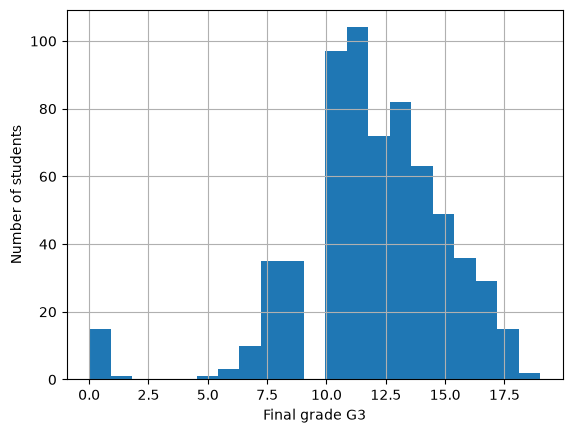

In [3]:
df["G3"].describe()
df["G3"].hist(bins=21)
plt.xlabel("Final grade G3")
plt.ylabel("Number of students")
plt.show()

In [4]:
print((df["G3"] == 0).sum(), "students with G3 = 0")
print((df["G3"] < 10).sum(), "students failing (G3 < 10)")
df[df["G3"] == 0][["G1", "G2", "G3", "absences"]]

15 students with G3 = 0
100 students failing (G3 < 10)


,G1,G2,G3,absences
163,11,9,0,0
440,7,0,0,0
519,8,7,0,0
563,7,0,0,0
567,4,0,0,0
583,8,6,0,0
586,8,8,0,0
597,9,0,0,0
603,5,0,0,0
605,5,0,0,0


In [5]:
df[["G1", "G2", "G3"]].corr()


,G1,G2,G3
G1,1.000000,0.864982,0.826387
G2,0.864982,1.000000,0.918548
G3,0.826387,0.918548,1.000000


In [6]:
for col in df.select_dtypes(exclude="number").columns:
    print(col, df[col].unique())


school <StringArray>
['GP', 'MS']
Length: 2, dtype: str
sex <StringArray>
['F', 'M']
Length: 2, dtype: str
address <StringArray>
['U', 'R']
Length: 2, dtype: str
famsize <StringArray>
['GT3', 'LE3']
Length: 2, dtype: str
Pstatus <StringArray>
['A', 'T']
Length: 2, dtype: str
Mjob <StringArray>
['at_home', 'health', 'other', 'services', 'teacher']
Length: 5, dtype: str
Fjob <StringArray>
['teacher', 'other', 'services', 'health', 'at_home']
Length: 5, dtype: str
reason <StringArray>
['course', 'other', 'home', 'reputation']
Length: 4, dtype: str
guardian <StringArray>
['mother', 'father', 'other']
Length: 3, dtype: str
schoolsup <StringArray>
['yes', 'no']
Length: 2, dtype: str
famsup <StringArray>
['no', 'yes']
Length: 2, dtype: str
paid <StringArray>
['no', 'yes']
Length: 2, dtype: str
activities <StringArray>
['no', 'yes']
Length: 2, dtype: str
nursery <StringArray>
['yes', 'no']
Length: 2, dtype: str
higher <StringArray>
['yes', 'no']
Length: 2, dtype: str
internet <StringArray>
['n

## Cleaning decisions

- **G1 and G2 are dropped**: they are only known during the year, but our tool is used at the start of the year (leakage).
- **The 15 students with G3 = 0 are dropped**: all of them have 0 absences, so they most likely never sat the final exam. The tool predicts the grade of students who sit the exam.

In [7]:
%load_ext autoreload
%autoreload 2

from student_performance.data import DatasetLoader

In [8]:
loader = DatasetLoader("../data/raw/student-por.csv", drop_columns=["G1", "G2"])
df_clean = loader.clean(loader.load())
X_train, X_test, y_train, y_test = loader.split(df_clean)

print("Cleaned:", df_clean.shape)
print("Train:", X_train.shape, " Test:", X_test.shape)

Cleaned: (634, 31)
Train: (507, 30)  Test: (127, 30)


In [9]:
print("Fail rate in train:", round((y_train < 10).mean(), 3))
print("Fail rate in test: ", round((y_test < 10).mean(), 3))

Fail rate in train: 0.134
Fail rate in test:  0.134


The split is done once, 80/20, stratified on pass/fail so both sets keep the same fail rate (13.4 %). From here on, the test set is not touched until the final evaluation.

## Preprocessing

Every column is prepared inside one `ColumnTransformer` (`build_preprocessor` in `features.py`):

- **13 numeric columns** (`age`, `Medu`, `studytime`, `failures`, `absences`, ...) are standardised with `StandardScaler`, so that Ridge, Lasso, k-NN and SVR treat them on the same scale. The 1–5 scales are ordered, so they stay as numbers.
- **17 text columns** are one-hot encoded. The 13 two-value columns (yes/no, F/M, ...) become a single 0/1 column; `Mjob`, `Fjob`, `reason` and `guardian` get one column per value.

The transformer is always fitted on training data only. Inside cross-validation it sits in a `Pipeline`, so each fold's scaler only sees that fold's training rows (no leakage).

In [10]:
from student_performance.features import build_preprocessor

preprocessor = build_preprocessor()
X_train_prepared = preprocessor.fit_transform(X_train)

print("Before:", X_train.shape, " After:", X_train_prepared.shape)

Before: (507, 30)  After: (507, 43)


In [11]:
list(preprocessor.get_feature_names_out())

['num__age',
 'num__Medu',
 'num__Fedu',
 'num__traveltime',
 'num__studytime',
 'num__failures',
 'num__famrel',
 'num__freetime',
 'num__goout',
 'num__Dalc',
 'num__Walc',
 'num__health',
 'num__absences',
 'cat__school_MS',
 'cat__sex_M',
 'cat__address_U',
 'cat__famsize_LE3',
 'cat__Pstatus_T',
 'cat__Mjob_at_home',
 'cat__Mjob_health',
 'cat__Mjob_other',
 'cat__Mjob_services',
 'cat__Mjob_teacher',
 'cat__Fjob_at_home',
 'cat__Fjob_health',
 'cat__Fjob_other',
 'cat__Fjob_services',
 'cat__Fjob_teacher',
 'cat__reason_course',
 'cat__reason_home',
 'cat__reason_other',
 'cat__reason_reputation',
 'cat__guardian_father',
 'cat__guardian_mother',
 'cat__guardian_other',
 'cat__schoolsup_yes',
 'cat__famsup_yes',
 'cat__paid_yes',
 'cat__activities_yes',
 'cat__nursery_yes',
 'cat__higher_yes',
 'cat__internet_yes',
 'cat__romantic_yes']

30 input columns become 43 model features: 13 scaled numeric columns, 13 binary columns, and 17 columns for the four nominal variables (5 + 5 + 4 + 3).

## Baseline

Metric: **MAE** (average error in grade points). 5-fold CV on the training set only.

In [12]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

from student_performance.models import Trainer

trainer = Trainer(n_splits=5, seed=42)
baseline = trainer.compare(
    {"Dummy (mean)": DummyRegressor(), "Linear regression": LinearRegression()},
    X_train,
    y_train,
)
baseline.round(3)

,mae,mae_std,rmse
Linear regression,1.847,0.098,2.331
Dummy (mean),2.255,0.114,2.737


Predicting the mean for everyone gives MAE ≈ 2.26. Linear regression reduces it to ≈ 1.85: the background columns carry real signal. This is the score to beat.

## Model comparison

Five models, each tuned with `GridSearchCV` on the same 5 folds of the training set. Grids are in `config.yaml`.

In [13]:
from student_performance.config import load_config
from student_performance.models import candidate_models

config = load_config("../config.yaml")
trainer = Trainer(n_splits=config["cv"]["n_splits"], seed=config["seed"])
candidates = candidate_models(config["grids"], config["seed"])
comparison = trainer.select_best(candidates, X_train, y_train)
comparison.round(3)

,mae,mae_std,rmse,best_params
huber,1.825,0.104,2.297,"{'alpha': 10, 'epsilon': 2.0}"
ridge,1.827,0.099,2.308,{'alpha': 10}
lasso,1.831,0.103,2.307,{'alpha': 0.03}
linear_svr,1.887,0.117,2.356,{'C': 1}
knn,1.893,0.104,2.351,"{'n_neighbors': 10, 'weights': 'distance'}"


Huber, Ridge and Lasso are tied (MAE ≈ 1.83, differences far below the fold-to-fold spread of ≈ 0.10); k-NN and linear SVR are slightly worse. All beat the baseline (2.26).

**Chosen: Huber regression.** Its loss is squared for small errors and linear for large ones, so a few students with unexpectedly low or high grades pull the model less than with MSE. Being linear, it can also be interpreted through its coefficients.

## Decision threshold

The tool flags a student when the predicted grade is below a threshold. Goal: **catch at least 75 % of the students who will fail**, since a missed student gets no help, while an unnecessary flag only costs a meeting. The threshold is chosen on **out-of-fold predictions** of the training set (each student predicted by a model that never saw them).

In [14]:
from student_performance.evaluate import choose_threshold, flag_metrics

out_of_fold = trainer.out_of_fold_predictions(X_train, y_train)
pd.DataFrame(
    {t: flag_metrics(y_train, out_of_fold, t) for t in [10, 10.5, 11, 11.5, 12]}
).T.round(2)

,recall,precision,flagged_share
10.0,0.32,0.47,0.09
10.5,0.41,0.41,0.13
11.0,0.66,0.42,0.21
11.5,0.79,0.36,0.29
12.0,0.84,0.29,0.39


In [15]:
threshold = choose_threshold(y_train, out_of_fold, config["decision"]["target_recall"])
threshold

11.3

Flagging at the pass mark (10) would catch only about a third of failing students: predictions are pulled towards the average. A threshold of 11.3 reaches the 75 % goal while flagging a quarter of students.

## Final test (used once)

In [16]:
from student_performance.evaluate import flag_table, plot_residuals, regression_metrics

y_pred = trainer.pipeline.predict(X_test)
print(regression_metrics(y_test, y_pred))
print(flag_metrics(y_test, y_pred, threshold))
flag_table(y_test, y_pred, threshold)

{'mae': 1.663794264601692, 'rmse': 2.12412447143302}
{'recall': 0.6470588235294118, 'precision': 0.3333333333333333, 'flagged_share': 0.25984251968503935}


tool,flagged,not flagged
actual,,
fails,11,6
passes,22,88


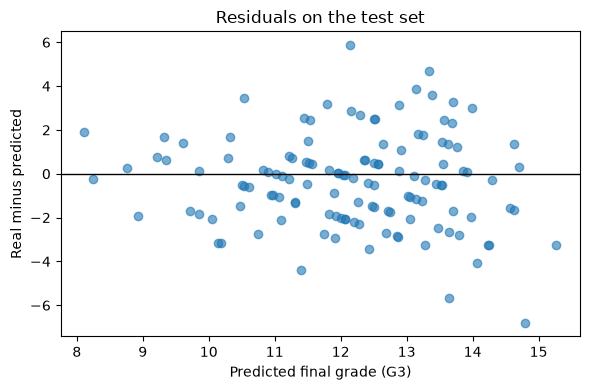

In [17]:
fig = plot_residuals(y_test, y_pred)

Test MAE is **1.66** grade points (RMSE 2.12), in line with cross-validation: the model was not overfitted. On the 127 test students, the flag catches 11 of the 17 who fail (65 %), below the 75 % reached in cross-validation: with only 17 failing students, one or two students change this a lot. The residual plot shows predictions squeezed between 8 and 15: the model under-predicts the best students and over-predicts the weakest.

## Interpretation

In [18]:
from student_performance.evaluate import top_coefficients

top_coefficients(trainer.pipeline, n=10).round(2)

,coefficient
cat__higher_yes,1.15
cat__schoolsup_yes,-0.80
cat__school_MS,-0.67
num__failures,-0.66
cat__sex_M,-0.48
num__age,0.39
cat__romantic_yes,-0.38
cat__Mjob_health,0.38
num__absences,-0.36
num__Medu,0.33


Numeric features are standardised, so their coefficient is the change in predicted grade for one standard deviation; for yes/no features it is the difference between the two groups, all else equal.

- **Wanting higher education** (+1.15 points) is the strongest positive signal.
- **Past failures** (−0.66 per std) and **absences** (−0.36) lower the prediction.
- **Extra school support** (−0.80) is negative: not because support hurts, but because the school gives it to students who already struggle. Coefficients show associations, not causes.
- **School MS** (−0.67) and **being male** (−0.48) are also associated with lower grades.

## Limits

1. **Modest accuracy**: about 1.7 points of error on a 0–20 scale, and predictions stay close to the average, so the tool ranks students more than it predicts exact grades.
2. **Small, local data**: 634 students from two Portuguese schools in 2005–06; the model may not transfer to other schools, countries or years.

## Risks of using it on real students

A flag is a prediction, not a judgement: on the test set, 2 in 3 flagged students in fact passed and 1 in 3 failing students was missed, so it should only trigger an offer of support, never a sanction or a lower expectation. The model uses sensitive information (sex, family situation, parents' jobs, alcohol use, relationships): it can reproduce existing inequalities, for example flagging boys or MS students more often, and collecting such data requires consent and careful protection under GDPR. A counsellor should always review the flag.